# Analysis of processed data of Consumer Complaint

### In the previous notebook data was pre-processed for the proper analysis.

Selected features consist of:
*   Product
*   Sub-product
*   Issue
*   Sub-issue
*   Company
*   State
*   Submitted via
*   Company public response
*   Consumer consent provided?
*   Company response to consumer



In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import plotly.express as px
import plotly.graph_objects as go
import seaborn as sns
from typing import Dict, List, Any, Tuple, Optional
from scipy.stats import chi2_contingency
from sklearn.feature_selection import mutual_info_classif
from sklearn.preprocessing import LabelEncoder
import time
from tqdm import tqdm

In [ ]:
df = pd.read_parquet("https://cfpb-project-742435394310-us-east-1-an.s3.us-east-1.amazonaws.com/processed/processed_data.parquet")

In [ ]:
df.isnull().sum()

,0
Product,0
Issue,0
Company,0
Submitted via,0
Consumer consent provided?,0
Company response to consumer,0


In [ ]:
f'''
The amount of the products is around {len(df['Product'].unique())}, while the amount of sub-product is {len(df['Sub-product'])}.
Moreover, the amount of issues is {len(df['Issue'].unique())}, while the amount of the sub-issues is {len(df['Sub-issue'])}
To see the balance inside given classes the graphs below are presented.
'''

'\nThe amount of the products is around 21, while the amount of sub-product is 14290253. \nMoreover, the amount of issues is 178, while the amount of the sub-issues is 14290253\nTo see the balance inside given classes the graphs below are presented.\n'

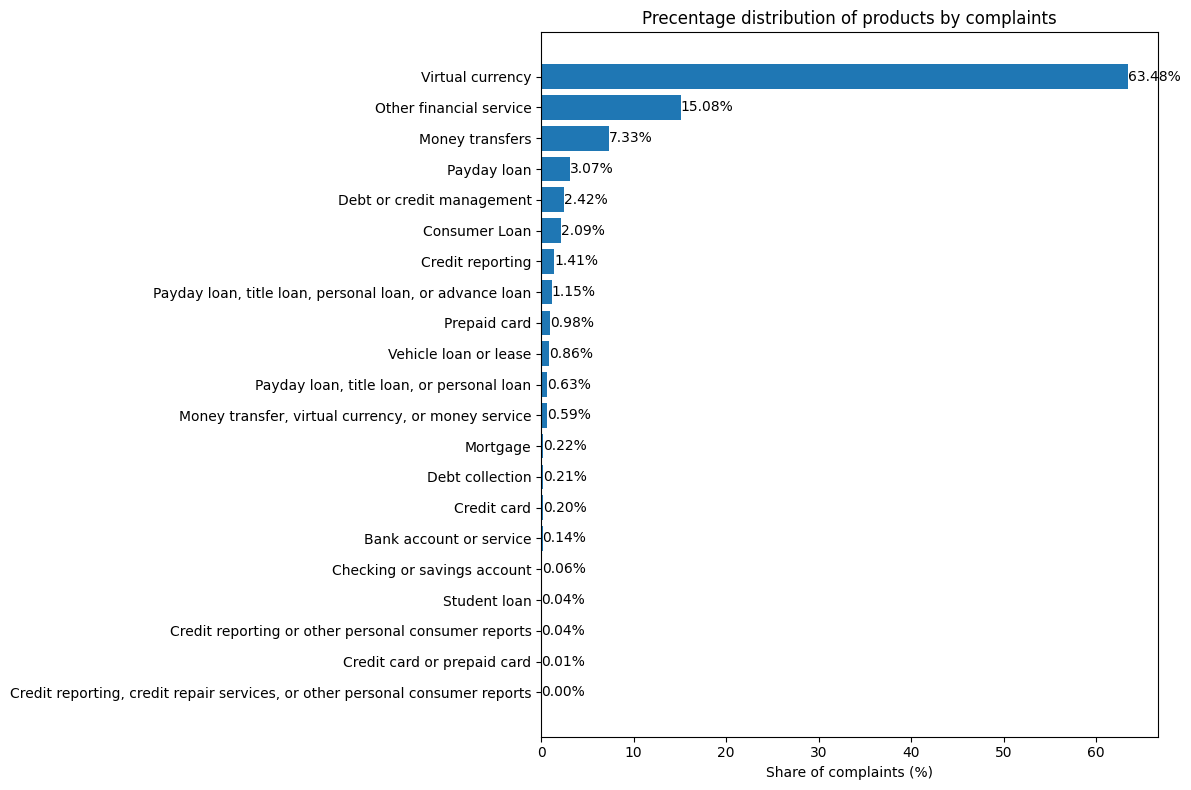

In [ ]:
products = df['Product'].unique()

products_precentage = round((df['Product'].value_counts()/df['Product'].value_counts().sum())*100, 3)

products_precentage = products_precentage.sort_values()

plt.figure(figsize=(12, 8))

product_bar = plt.barh(products, products_precentage)

plt.xlabel("Share of complaints (%)")
plt.title("Precentage distribution of products by complaints")

for bar, value in zip(product_bar, products_precentage.values):
  plt.text(
          value,
          bar.get_y() + bar.get_height() / 2,
          f'{value:.2f}%',
          va = 'center'
  )
  plt.tight_layout()

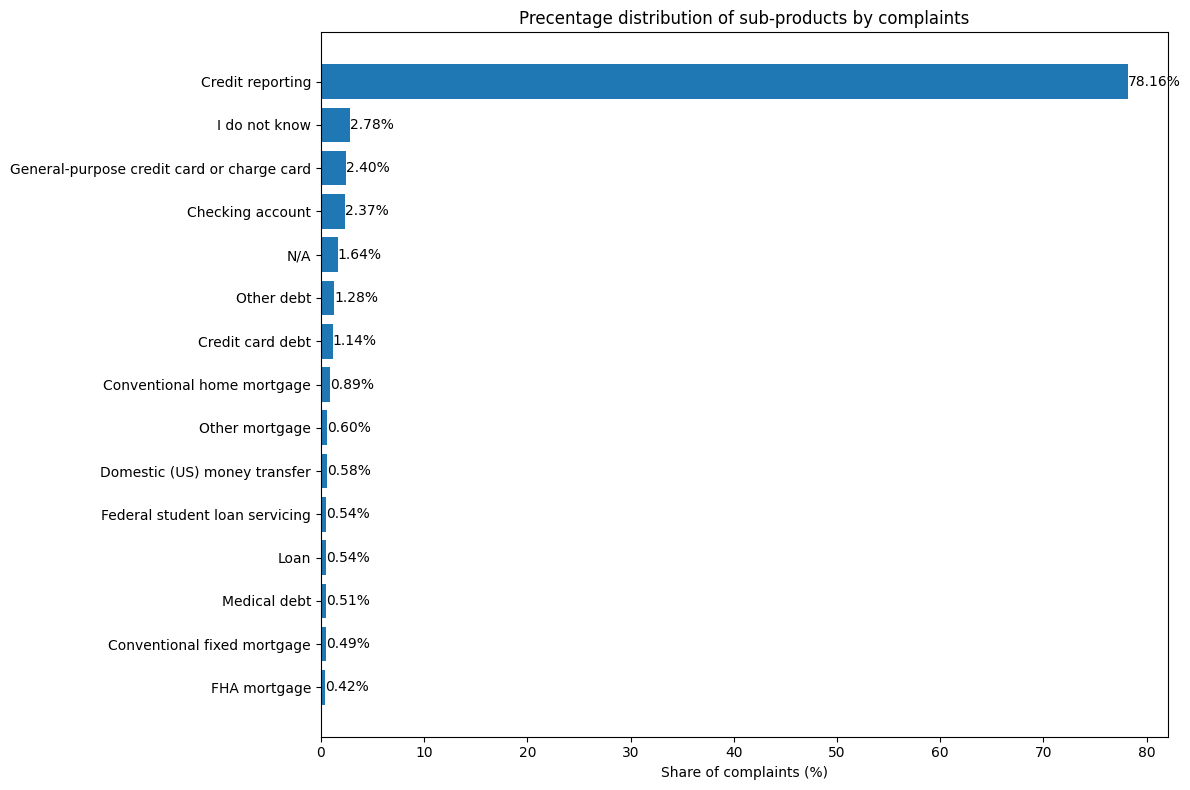

In [ ]:
sub_products_precentage = ((df['Sub-product'].value_counts()/df['Sub-product'].value_counts().sum())*100)

sub_products_precentage_top = sub_products_precentage.head(15)

sub_products_precentage_top = sub_products_precentage_top.sort_values()

plt.figure(figsize=(12, 8))

sub_products_graph = plt.barh(sub_products_precentage_top.index, sub_products_precentage_top.values)

plt.xlabel("Share of complaints (%)")
plt.title('Precentage distribution of sub-products by complaints')

for bar, value in zip(sub_products_graph, sub_products_precentage_top.values):
  plt.text(
          value,
          bar.get_y() + bar.get_height() / 2,
          f'{value:.2f}%',
          va = 'center'
  )
  plt.tight_layout()

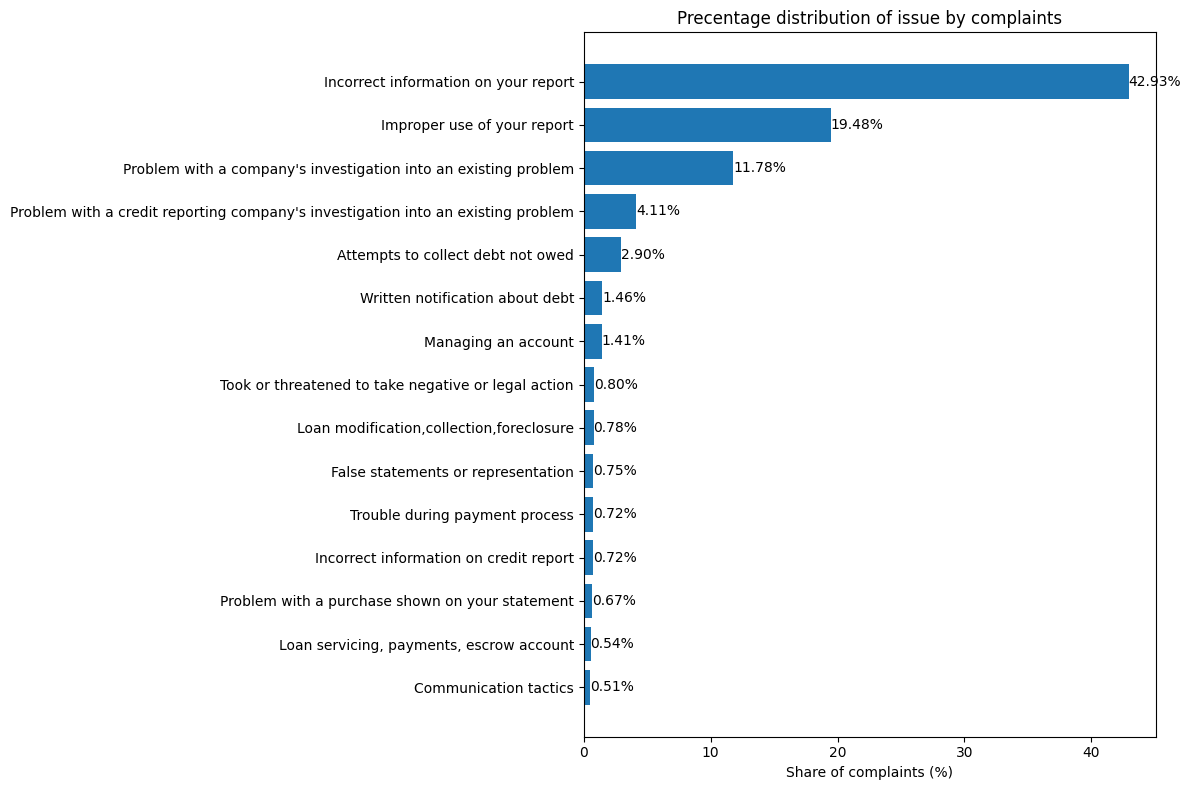

In [ ]:
issue_percentage = ((df['Issue'].value_counts()/df['Issue'].value_counts().sum())*100)

plt.figure(figsize= (12, 8))

issue_percentage_top = issue_percentage.head(15)

issue_percentage_top = issue_percentage_top.sort_values()

issue_percentage_barh = plt.barh(issue_percentage_top.index, issue_percentage_top.values)

plt.xlabel('Share of complaints (%)')
plt.title('Precentage distribution of issue by complaints')

for bar,value in zip(issue_percentage_barh, issue_percentage_top.values):
  plt.text(
          value,
          bar.get_y() + bar.get_height() / 2,
          f'{value:.2f}%',
          va = 'center'
  )
  plt.tight_layout()

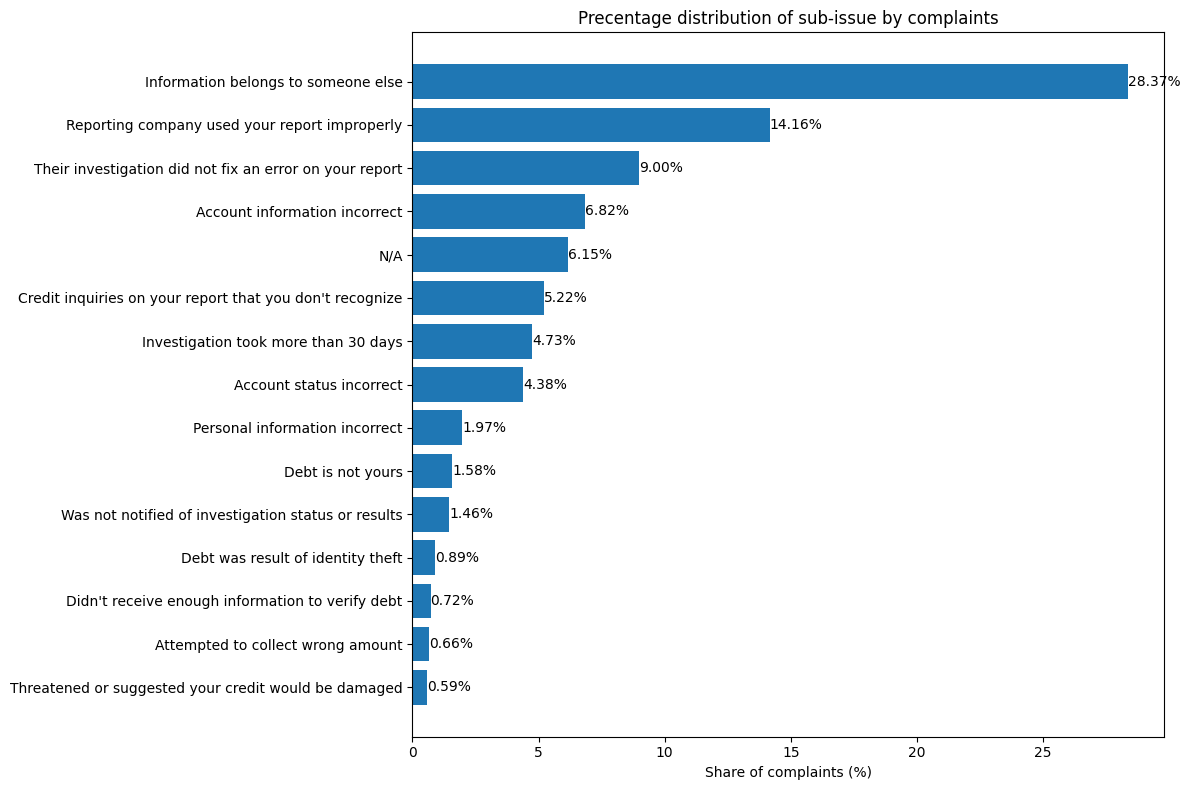

In [ ]:
sub_issue_prec = ((df['Sub-issue'].value_counts()/df['Sub-issue'].value_counts().sum())*100)

plt.figure(figsize= (12,8))

sub_issue_perc_top = sub_issue_prec.head(15)

sub_issue_perc_top = sub_issue_perc_top.sort_values()

sub_issue_percentage_barh = plt.barh(sub_issue_perc_top.index, sub_issue_perc_top.values)

plt.xlabel('Share of complaints (%)')
plt.title('Precentage distribution of sub-issue by complaints')

for bar,value in zip(sub_issue_percentage_barh, sub_issue_perc_top.values):
  plt.text(
          value,
          bar.get_y() + bar.get_height() / 2,
          f'{value:.2f}%',
          va = 'center'
  )
  plt.tight_layout()

### For the product the most compliants are about virtual currency, money transfers and payday loans, whereas for sub-products, one category dominates: credit information. The issues are mostly divided by incorrect information or improper use of the report, along with dissatisfaction with the company's investigation into existing problems. In the sub-issue category, most of the concern originates from inaccurate information and the failure to resolve the matter in question.  

In [ ]:
f'Number of companies against which a complaint was filed: {len(df['Company'].unique())}'

'Number of companies against which a complaint was filed: 7815'

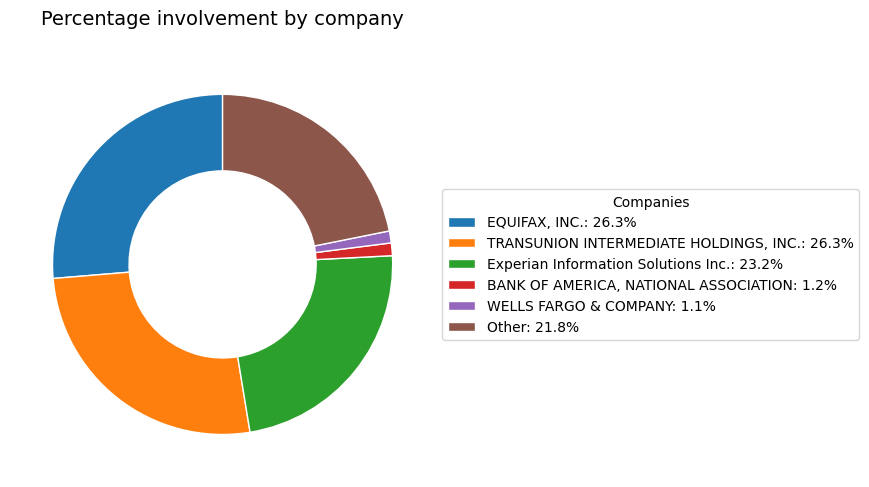

In [ ]:
#Calculating the % share of top 5 companies and sumarizing rest due to large number of companies
company_prec_share = (df['Company'].value_counts()/df['Company'].value_counts().sum())*100
company_prec_share_top_5 = company_prec_share[:5]
others = company_prec_share[5:].sum()
company_prec_share_top_5['Other'] = others


legend_labels = [
    f"{company}: {share:.1f}%"
    for company, share in company_prec_share_top_5.items()
]

#Create figure
fig, ax = plt.subplots(figsize=(8, 6), subplot_kw=dict(aspect="equal"))

wedges, _ = ax.pie(
    company_prec_share_top_5,
    startangle=90,
    wedgeprops=dict(width=0.45, edgecolor="white")
)


ax.legend(
    wedges,
    legend_labels,
    title="Companies",
    loc="center left",
    bbox_to_anchor=(1, 0.5)
)

ax.set_title("Percentage involvement by company", fontsize=14, pad=20)

plt.tight_layout()
plt.show()

In [ ]:
company_prec_share_top_5[:3].sum()

np.float64(75.81930844751314)

### Three companies (Equifax, TransUnion Intermediate Holdings, and Experian Information Solutions) receive the most attention, as they account for 75.8% of complaints.

In [ ]:
state_totals = (
    df
    .groupby('State')
    .size()
    .reset_index(name="Total complaints")
)

state_response_counts = (
    df
    .groupby(['State', 'Company response to consumer'])
    .size()
    .reset_index(name="Count")
)

hover_text = []

for state in state_totals['State']:
    temp = state_response_counts[state_response_counts['State'] == state]
    temp = temp.sort_values("Count", ascending=False)

    total = state_totals.loc[
        state_totals['State'] == state,
        "Total complaints"
    ].iloc[0]

    lines = [f"<b>{state}</b>", f"Total complaints: {total:,}", "<br><b>Responses:</b>"]

    for _, row in temp.head(5).iterrows():
        pct = row["Count"] / total * 100
        lines.append(f"{row['Company response to consumer']}: {row['Count']:,} ({pct:.1f}%)")

    hover_text.append("<br>".join(lines))

state_totals["Hover text"] = hover_text

fig = px.choropleth(
    state_totals,
    locations=state_totals['State'],
    locationmode="USA-states",
    color="Total complaints",
    scope="usa",
    hover_name=state_totals['State'],
    hover_data={
        "State": False,
        "Total complaints": True,
        "Hover text": False
    },
    color_continuous_scale="Blues",
    title="CFPB Complaints by State with Company Response Breakdown"
)

fig.update_traces(
    hovertemplate="%{customdata[0]}<extra></extra>",
    customdata=state_totals[["Hover text"]]
)

fig.update_layout(
    title_x=0.5,
    geo=dict(
        lakecolor="white",
        bgcolor="rgba(0,0,0,0)"
    ),
    margin=dict(l=20, r=20, t=70, b=20)
)

fig.show()

/tmp/ipykernel_3307/3825554424.py:3: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby('State')
/tmp/ipykernel_3307/3825554424.py:10: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby(['State', 'Company response to consumer'])


“Closed with relief” and “Closed without relief” are legacy response categories that were replaced on June 1, 2012. Because they are no longer used for new complaints, they were excluded from the model used to predict a company’s response to a consumer.

In [ ]:
df = df.drop(
    df.loc[
        (df['Company response to consumer'] == "Closed with relief")|
        (df['Company response to consumer'] == "Closed without relief")
        ].index
    )


In [ ]:
df["Company response to consumer"] = (
    df["Company response to consumer"]
    .cat.remove_categories([
        "Closed with relief",
        "Closed without relief"
    ])
)

In [ ]:
print(df['Company response to consumer'].unique())

['Closed with explanation', 'Closed with non-monetary relief', 'Closed with monetary relief', 'Untimely response', 'In progress', 'Closed']
Categories (6, object): ['Closed', 'Closed with explanation', 'Closed with monetary relief',
                         'Closed with non-monetary relief', 'In progress', 'Untimely response']


In [ ]:
company_response_prec = (df['Company response to consumer'].value_counts()/df['Company response to consumer'].value_counts().sum())*100

company_response_prec_sorted = company_response_prec.sort_values(
    ascending=True
)

fig = go.Figure(
    go.Bar(
        x=company_response_prec_sorted.values,
        y=company_response_prec_sorted.index,
        orientation="h",
        text=[
            f"{value:.1f}%"
            for value in company_response_prec_sorted.values
        ],
        textposition="outside",
        hovertemplate=(
            "<b>%{y}</b><br>"
            "Percentage: %{x:.2f}%"
            "<extra></extra>"
        ),
    )
)

fig.update_layout(
    title={
        "text": "Balance of Company Response Categories",
        "x": 0.5,
        "xanchor": "center",
    },
    xaxis_title="Percentage of complaints",
    yaxis_title="Company response to consumer",
    height=500,
    margin={
        "l": 220,
        "r": 40,
        "t": 80,
        "b": 50,
    },
)

fig.show()

### The distribution of company responses is strongly imbalanced. The majority of complaints were closed with explanation, representing approximately 59.8% of all cases, followed by closed with non-monetary relief at 35.5%. All other response categories account for only a small share of the dataset, with monetary relief representing just 1.4%. This suggests that companies most commonly respond by explaining the issue rather than providing direct financial compensation.

In [ ]:
response_by_company = (
    df.groupby(['Company', 'Company response to consumer'])
    .size()
    .reset_index(name='Count')
)

response_by_company['Count'] = round((response_by_company['Count']/response_by_company['Count'].sum())*100, 2)

response_by_company = response_by_company.loc[
    (response_by_company["Company"] == "Experian Information Solutions Inc.")
    | (response_by_company["Company"] == "TRANSUNION INTERMEDIATE HOLDINGS, INC.")
    | (response_by_company["Company"] == "EQUIFAX, INC.")
]



fig = px.bar(response_by_company, x="Company", y="Count", color="Company response to consumer", title="The response per firm")

fig.update_layout(
    title={
        "text": "Company Response Distribution for Major Credit Bureaus",
        "x": 0.5,
        "xanchor": "center",
    },
    xaxis_title="Percentage of complaints",
    yaxis_title="Company",
    legend_title="Company response",
    barmode="stack",
    width=900,
    height=450,
    margin={
        "l": 100,
        "r": 200,
        "t": 70,
        "b": 80,
    },
)

fig.show()

/tmp/ipykernel_3307/2811143502.py:2: FutureWarning:

The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.



### Only the three largest companies are listed, as they account for 75% of the complaints. The company response distribution shows clear differences among the three major credit bureaus. Experian resolves most complaints by closing them with an explanation, while TransUnion has a much higher proportion of complaints closed with non-monetary relief. Equifax shows a more balanced response pattern between explanation and non-monetary relief. Overall, the results suggest that direct monetary compensation is uncommon, and most complaints are resolved through explanations or non-financial corrective actions.

In [ ]:
def chi_square_test(df: pd.DataFrame, feature: str, target: str = "Company response to consumer") -> Dict[str, Any]:
    """
    Chi-Square Test + Cramér's V for one feature.

    To determine whether there is a statistically significant relationship
    between a given feature (e.g., ‘Product’) and the target (‘Company response to consumer’).
    """
    crosstab = pd.crosstab(df[feature], df[target])

    if crosstab.shape[0] < 2 or crosstab.shape[1] < 2:
       return {
            "feature": feature,
            "cramers_v": 0.0,
            "significant": False,
            "note": "Too few features"
       }

    chi2_stat, p_value, _, _ = chi2_contingency(crosstab, correction= True)

    n = crosstab.sum().sum()
    min_dim = min(crosstab.shape) - 1
    cramers_v = np.sqrt(chi2_stat / (n * min_dim)) if min_dim > 0 else 0.0

    intepretation = (
        'Very strong' if cramers_v > 0.5 else
        'Strong'      if cramers_v > 0.3 else
        'Medium'      if cramers_v > 0.1 else
        'Weak'
    )

    return {
        "feature": feature,
        "chi2_stat": f"{round(chi2_stat, 2)}",
        "p_value": f"{p_value:.2e}",
        "cramers_v": f"{round(cramers_v, 2)}",
        "significant": p_value < 0.05,
        "intepretation": intepretation
    }


In [ ]:
columns = df.columns.to_list()
columns.pop()

df_chi_results = pd.DataFrame()

for col in columns:
  result = (chi_square_test(df, feature= col))
  df_chi_results = pd.concat([df_chi_results, pd.DataFrame([result])], ignore_index=True)

df_chi_results

,feature,chi2_stat,p_value,cramers_v,significant,intepretation
0,Product,3742621.73,0.00e+00,0.19,True,Medium
1,Sub-product,3803051.88,0.00e+00,0.19,True,Medium
2,Issue,5159088.09,0.00e+00,0.23,True,Medium
3,Sub-issue,4023528.83,0.00e+00,0.2,True,Medium
4,Company,15944034.25,0.00e+00,0.4,True,Strong
5,State,125166.29,0.00e+00,0.04,True,Weak
6,Submitted via,600882.19,0.00e+00,0.08,True,Weak
7,Company public response,747919.88,0.00e+00,0.09,True,Weak
8,Consumer consent provided?,2928291.18,0.00e+00,0.23,True,Medium


### The Chi-Square test and Cramer’s V were used to examine the relationship between the target variable and the features. All features had a p-value below 0.05, indicating a statistically significant association with the target variable. Based on Cramer’s V, the most influential feature was “Company.” Among the features with weak influence, “State,” “Submitted via,” and “Company public response” showed relatively lower association with the target variable.

In [ ]:
def calculate_mutual_information(df: pd.DataFrame, target: str = "Company response to consumer") -> pd.DataFrame:
  X = df.drop(columns = [target])
  y = df[target]

  X_encoded = X.copy()
  le = LabelEncoder()

  for col in X_encoded.columns:
    X_encoded[col] = le.fit_transform(X_encoded[col])

  y_encoded = le.fit_transform(y)

  mi_scores = mutual_info_classif(X_encoded, y_encoded, discrete_features=True, random_state=42)

  mi_scores_int = []
  for score in mi_scores:
      if score > 0.5:
          mi_scores_int.append('Strong')
      elif score > 0.3:
          mi_scores_int.append('Good')
      elif score > 0.1:
          mi_scores_int.append('Moderate')
      elif score > 0.05:
          mi_scores_int.append('Weak')
      elif score > 0:
          mi_scores_int.append('Very Weak')
      else:
          mi_scores_int.append('No relationship')

  return pd.DataFrame({
      'feature': X.columns,
      'mutual_information': mi_scores,
      'intepretation': mi_scores_int
  }).sort_values(by='mutual_information', ascending = False).reset_index(drop = True)


mi_values = calculate_mutual_information(df)
mi_values

,feature,mutual_information,intepretation
0,Company,0.205042,Moderate
1,Product,0.091188,Weak
2,Issue,0.089325,Weak
3,Sub-issue,0.084506,Weak
4,Sub-product,0.080144,Weak
5,Consumer consent provided?,0.074035,Weak
6,Company public response,0.032183,Very Weak
7,Submitted via,0.012691,Very Weak
8,State,0.004132,Very Weak


### The Mutual Information results are consistent with the findings from the Chi-Square test and Cramer’s V. They also indicate that “Company” is the most influential feature, while “State” has the weakest relationship with the target variable.

In [ ]:
def theils_u_matrix_optimized(df: pd.DataFrame,
                             columns: Optional[list] = None,
                             decimals: int = 4,
                             min_entropy: float = 0.01) -> pd.DataFrame:

    start_time = time.time()

    if columns is None:
        columns = df.columns.tolist()

    # Precompute entropy for all columns
    def entropy(series: pd.Series) -> float:
        p = series.value_counts(normalize=True)
        return -np.sum(p * np.log2(p + 1e-10))

    print("Computing entropy for all columns...")
    entropies = {col: entropy(df[col]) for col in columns}

    # Initialize matrix
    matrix = pd.DataFrame(index=columns, columns=columns, dtype=float)

    print(f"Computing Theil's U for {len(columns)} columns...")

    for i, x_col in enumerate(tqdm(columns)):
        for j, y_col in enumerate(columns):
            if i == j:
                matrix.loc[x_col, y_col] = 1.0
                continue

            H_y = entropies[y_col]
            if H_y < min_entropy:
                matrix.loc[x_col, y_col] = 0.0
                continue

            grouped = df.groupby(x_col, observed=True)[y_col]
            H_y_given_x = 0.0
            total_valid = len(df[y_col])

            for _, subset in grouped:
                if len(subset) > 0:
                    weight = len(subset) / total_valid
                    H_y_given_x += weight * entropy(subset)

            theils_u = (H_y - H_y_given_x) / H_y if H_y > 0 else 0.0
            matrix.loc[x_col, y_col] = round(theils_u, decimals)

    print(f"✅ Theil's U matrix computed in {time.time() - start_time:.1f} seconds")
    return matrix

x = theils_u_matrix_optimized(df)

x

Computing entropy for all columns...
Computing Theil's U for 10 columns...


100%|██████████| 10/10 [01:26<00:00,  8.70s/it]

✅ Theil's U matrix computed in 87.6 seconds


,Product,Sub-product,Issue,Sub-issue,Company,State,Submitted via,Company public response,Consumer consent provided?,Company response to consumer
Product,1.0000,0.7430,0.4427,0.2820,0.2087,0.0059,0.2576,0.0837,0.0758,0.1050
Sub-product,0.6794,1.0000,0.4212,0.2901,0.2298,0.0063,0.2766,0.0898,0.0676,0.0923
Issue,0.7261,0.7554,1.0000,0.6687,0.2178,0.0072,0.2651,0.0918,0.0765,0.1029
Sub-issue,0.5929,0.6672,0.8573,1.0000,0.2020,0.0091,0.2525,0.0868,0.0732,0.0973
Company,0.4127,0.4970,0.2626,0.1900,1.0000,0.0221,0.2167,0.7555,0.0548,0.2361
State,0.0136,0.0159,0.0101,0.0100,0.0257,1.0000,0.0181,0.0026,0.0045,0.0048
Submitted via,0.0417,0.0490,0.0262,0.0194,0.0177,0.0013,1.0000,0.0062,0.0792,0.0146
Company public response,0.0502,0.0589,0.0336,0.0248,0.2292,0.0007,0.0228,1.0000,0.0285,0.0371
Consumer consent provided?,0.0588,0.0573,0.0362,0.0270,0.0215,0.0015,0.3791,0.0368,1.0000,0.0853
Company response to consumer,0.0669,0.0643,0.0400,0.0295,0.0761,0.0013,0.0575,0.0394,0.0701,1.0000


In [ ]:
def get_top_bottom_5_theil (df: pd.DataFrame):
  pairs = []
  for index in df.index:
    for col in df.columns:
      if index != col:
        pairs.append({'Explains': index, 'Explained': col, 'Theil_u': df.loc[index, col]})

  df_1 = pd.DataFrame(pairs).sort_values(by = 'Theil_u', ascending= False).head(5).set_index('Explains')
  df_2 = pd.DataFrame(pairs).sort_values(by = 'Theil_u', ascending= False).tail(5).set_index('Explains')

  return pd.concat([df_1, df_2])


In [ ]:
t_b_theil = get_top_bottom_5_theil(x)
t_b_theil

,Explained,Theil_u
Explains,,
Sub-issue,Issue,0.8573
Company,Company public response,0.7555
Issue,Sub-product,0.7554
Product,Sub-product,0.7430
Issue,Product,0.7261
State,Company public response,0.0026
Consumer consent provided?,State,0.0015
Submitted via,State,0.0013
Company response to consumer,State,0.0013


### Theil’s U was used to quantify the strength of association between nominal variables. The results indicate that “State” provides very limited information about the other features. In contrast, variables such as “Issue” and “Sub-issue” show a naturally strong association, which is expected given their related meanings.

In [ ]:
def cramer_v_matrix(df: pd.DataFrame) -> pd.DataFrame:

  start_time = time.time()

  columns = df.columns.to_list()

  matrix = pd.DataFrame(index=columns, columns=columns, dtype=float)

  for x_col in tqdm(columns):
    for y_col in columns:
      if x_col == y_col:
        matrix.loc[x_col, y_col] = 1
        continue

      crosstab = pd.crosstab(df[y_col], df[x_col])

      chi2_stat, p_value, _, _ = chi2_contingency(crosstab, correction= True)

      n = crosstab.sum().sum()
      min_dim = min(crosstab.shape) - 1
      cramers_v = np.sqrt(chi2_stat / (n * min_dim)) if min_dim > 0 else 0.0

      matrix.loc[x_col, y_col] = round(cramers_v, 2)

  print(f"✅ Cramers V matrix computed in {time.time() - start_time:.1f} seconds")
  return matrix



In [ ]:
cramer_v_mtr = cramer_v_matrix(df)
cramer_v_mtr

100%|██████████| 10/10 [02:38<00:00, 15.86s/it]

✅ Cramers V matrix computed in 158.6 seconds


,Product,Sub-product,Issue,Sub-issue,Company,State,Submitted via,Company public response,Consumer consent provided?,Company response to consumer
Product,1.00,0.75,0.81,0.58,0.48,0.04,0.19,0.14,0.21,0.19
Sub-product,0.75,1.00,0.45,0.32,0.34,0.03,0.23,0.15,0.21,0.19
Issue,0.81,0.45,1.00,0.53,0.21,0.03,0.21,0.15,0.22,0.23
Sub-issue,0.58,0.32,0.53,1.00,0.14,0.03,0.19,0.14,0.21,0.20
Company,0.48,0.34,0.21,0.14,1.00,0.10,0.18,0.48,0.18,0.40
State,0.04,0.03,0.03,0.03,0.10,1.00,0.04,0.02,0.05,0.04
Submitted via,0.19,0.23,0.21,0.19,0.18,0.04,1.00,0.05,0.25,0.08
Company public response,0.14,0.15,0.15,0.14,0.48,0.02,0.05,1.00,0.12,0.09
Consumer consent provided?,0.21,0.21,0.22,0.21,0.18,0.05,0.25,0.12,1.00,0.23
Company response to consumer,0.19,0.19,0.23,0.20,0.40,0.04,0.08,0.09,0.23,1.00


### The Cramer’s V results show the strength of association between the nominal variables. The strongest associations are observed between variables that are naturally related to the complaint structure. The highest relationship appears between “Product” and “Issue” with a value of 0.81, followed by “Product” and “Sub-product” with 0.75. This suggests a strong association between the type of financial product and the issue reported by the consumer.
### In contrast, “State” shows very weak associations with almost all other variables, with values mostly close to 0.03–0.05. This suggests that the consumer’s state is not strongly related to the other categorical features in the dataset.

### The features chosen to train mode:
*   Product
*   Issue
*   Company
*   Submitted via
*   Consumer consent provided?

### The Company's public response was not included as it could leak information about the Company's response to consumers.